# Conformal pillbox: FD, TD and eigenmode impedance validation

This notebook cross-validates the conformal FIT implementation in three complementary ways:

1. a driven frequency-domain impedance sweep,
2. a conventional time-domain wake simulation, and
3. a lossless eigenmode expansion of the longitudinal impedance.

The FD and TD calculations use identical conformal meshes. Three electric-field
monitor frequencies are additionally compared along the beam axis. The eigenmode
expansion uses the same reduced FD matrices, but reconstructs the impedance from a
finite set of source-free cavity modes rather than solving a driven system at every
frequency.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv
from scipy.constants import c as c_light
from scipy.signal import find_peaks

from wakis import GridFIT3D, SolverFIT3D, WakeSolver

try:
    from wakis import FieldMonitor
except ImportError:
    from wakis.field_monitors import FieldMonitor

try:
    from wakis import SolverFIT3D_FD
except ImportError:
    from wakis.solverFIT3D_FD import SolverFIT3D_FD

## Geometry and numerical parameters

The mesh is chosen from the shortest wavelength in the FD sweep,

\[
h_\mathrm{target}
=
\frac{c/f_\mathrm{max}}{N_\mathrm{pWl}}.
\]

Both solvers receive separately constructed but numerically identical
`GridFIT3D` objects. This avoids accidental solver-side state sharing while
keeping the mesh, geometry and conformal settings identical.

The TD calculation uses a Gaussian bunch and a finite wake length. Since the
PEC cavity is lossless, the TD resonance amplitudes are broadened by the finite
simulation time, while the direct FD solution approaches true poles. Resonance
positions and off-resonance agreement are therefore more meaningful than the
exact peak heights.


In [20]:
def find_repo_root(start=None):
    """Find the WAKIS repository root from the current working directory."""
    start = Path.cwd() if start is None else Path(start)

    for candidate in [start, *start.parents]:
        if (candidate / "wakis").exists() and (candidate / "tests").exists():
            return candidate

    raise FileNotFoundError(
        "Could not locate the WAKIS repository root. "
        "Run this notebook from inside the cloned WAKIS repository."
    )


repo_root = find_repo_root()

cavity_path = repo_root / "tests" / "stl" / "007_vacuum_cavity.stl"
shell_path = repo_root / "tests" / "stl" / "007_lossymetal_shell.stl"

stl_solids = {
    "cavity": str(cavity_path),
    "shell": str(shell_path),
}

stl_materials = {
    "cavity": "vacuum",
    "shell": "pec",
}

stl_material_types = {
    "cavity": "normal",
    "shell": "pec",
}

solids = pv.read(cavity_path) + pv.read(shell_path)
xmin, xmax, ymin, ymax, zmin, zmax = solids.bounds

Lx = xmax - xmin
Ly = ymax - ymin
Lz = zmax - zmin

# ---------------------------------------------------------------------------
# Frequency sweep / mesh
# ---------------------------------------------------------------------------

FMIN = 1.0e7
FMAX = 1.0e9
N_FREQ = 50

NPWL = 15
CONFORMAL_ETA = 0.2

# Conservative TD Courant factor for the conformal geometry. The current
# Cartesian CFL estimate does not yet account for shortened conformal metrics.
TD_CFLN = 0.1

# Eigenmode expansion. Shift-invert around the center of the two dominant
# pillbox resonances so that the curl-curl nullspace is avoided in this V1 test.
N_EIGENMODES = 12
EIGENMODE_TARGET_FREQUENCY = 0.70e9

wavelength_min = c_light / FMAX
target_h = wavelength_min / NPWL

Nx = max(1, int(np.ceil(Lx / target_h)))
Ny = max(1, int(np.ceil(Ly / target_h)))
Nz = max(1, int(np.ceil(Lz / target_h)))

dx = Lx / Nx
dy = Ly / Ny
dz = Lz / Nz

actual_npwl = wavelength_min / max(dx, dy, dz)

# ---------------------------------------------------------------------------
# Beam / wake
# ---------------------------------------------------------------------------

BETA = 1.0
Q = 1.0e-9
SIGMAZ = 0.1
WAKELENGTH = 10.0

XSOURCE = 0.0
YSOURCE = 0.0
XTEST = 0.0
YTEST = 0.0

# Keep the integration interval identical between TD and the current FD
# implementation. If boundary contamination becomes relevant later, introduce
# the same integration mask explicitly in both methods.
SKIP_CELLS = 0

# One low-frequency point and two frequencies near the visible resonances.
MONITOR_FREQUENCIES = np.array(
    [
        100.0e6,
        550.0e6,
        830.0e6,
    ]
)

bc_low = ["pec", "pec", "pec"]
bc_high = ["pec", "pec", "pec"]

print("Repository root:", repo_root)
print()
print("Geometry bounds:")
print(f"  x: [{xmin:.6g}, {xmax:.6g}] m")
print(f"  y: [{ymin:.6g}, {ymax:.6g}] m")
print(f"  z: [{zmin:.6g}, {zmax:.6g}] m")
print()
print(f"Requested NpWl : {NPWL}")
print(f"Actual NpWl    : {actual_npwl:.3f}")
print(f"TD CFL number  : {TD_CFLN:.3f}")
print(
    "Eigenmode target [MHz]:",
    EIGENMODE_TARGET_FREQUENCY / 1e6,
)
print(f"Requested eigenmodes: {N_EIGENMODES}")
print(f"Grid           : {Nx} x {Ny} x {Nz}")
print(f"dx,dy,dz [mm]  : {dx * 1e3:.3f}, {dy * 1e3:.3f}, {dz * 1e3:.3f}")
print()
print(
    "Field-monitor frequencies [MHz]:",
    MONITOR_FREQUENCIES / 1e6,
)

Repository root: /home/hschreib/Documents/Wakis/WAKIS

Geometry bounds:
  x: [-0.26, 0.26] m
  y: [-0.26, 0.26] m
  z: [-0.25, 0.55] m

Requested NpWl : 15
Actual NpWl    : 15.364
TD CFL number  : 0.100
Eigenmode target [MHz]: 700.0
Requested eigenmodes: 12
Grid           : 27 x 27 x 41
dx,dy,dz [mm]  : 19.259, 19.259, 19.512

Field-monitor frequencies [MHz]: [100. 550. 830.]


## Build identical conformal grids and both solvers

The grid construction is wrapped in a helper so that FD and TD use exactly the
same numerical geometry parameters without sharing one mutable grid object.


In [21]:
def build_grid():
    return GridFIT3D(
        xmin,
        xmax,
        ymin,
        ymax,
        zmin,
        zmax,
        Nx,
        Ny,
        Nz,
        stl_solids=stl_solids,
        stl_materials=stl_materials,
        stl_material_types=stl_material_types,
        stl_method="voxelize_rectilinear",
        geometry_mode="conformal",
        bg_material_type="pec",
        conformal_pec_snap_fraction=CONFORMAL_ETA,
        subpixel_smoothing=False,
        stl_scale=1.0,
        stl_rotate=[0.0, 0.0, 0.0],
        stl_translate=[0.0, 0.0, 0.0],
        verbose=1,
    )


grid_fd = build_grid()
grid_td = build_grid()

np.testing.assert_allclose(grid_fd.x, grid_td.x)
np.testing.assert_allclose(grid_fd.y, grid_td.y)
np.testing.assert_allclose(grid_fd.z, grid_td.z)

results_dir = repo_root / "notebooks" / "_013_fd_td_results"
results_dir.mkdir(parents=True, exist_ok=True)

td_ez_file = results_dir / "Ez_td.h5"
if td_ez_file.exists():
    td_ez_file.unlink()

wake_fd = WakeSolver(
    q=Q,
    sigmaz=SIGMAZ,
    beta=BETA,
    xsource=XSOURCE,
    ysource=YSOURCE,
    xtest=XTEST,
    ytest=YTEST,
    fmax=FMAX,
    skip_cells=SKIP_CELLS,
    save=False,
    verbose=1,
)

wake_td = WakeSolver(
    wakelength=WAKELENGTH,
    q=Q,
    sigmaz=SIGMAZ,
    beta=BETA,
    xsource=XSOURCE,
    ysource=YSOURCE,
    xtest=XTEST,
    ytest=YTEST,
    fmax=FMAX,
    skip_cells=SKIP_CELLS,
    save=False,
    Ez_file=str(td_ez_file),
    results_folder=str(results_dir) + "/",
    verbose=1,
)

solver_fd = SolverFIT3D_FD(
    grid_fd,
    wake=wake_fd,
    bc_low=bc_low,
    bc_high=bc_high,
    use_stl=True,
    bg="pec",
    dtype=np.float64,
    use_gpu=False,
    verbose=1,
)

solver_td = SolverFIT3D(
    grid_td,
    wake_td,
    bc_low=bc_low,
    bc_high=bc_high,
    use_stl=True,
    bg="pec",
    dtype=np.float64,
    use_gpu=False,
    cfln=TD_CFLN,
    verbose=1,
)

print()
print("FD operator dimensions:")
print(f"  full E space : {3 * solver_fd.N}")
print(f"  active E DOFs: {len(solver_fd.free_E_idx)}")
print(f"  C_red        : {solver_fd.C_red.shape}")
print(f"  Mnu          : {solver_fd.Mnu.shape}")
print(f"  Meps         : {solver_fd.Meps.shape}")
print(f"  Msigma       : {solver_fd.Msigma.shape}")
print(f"  SL           : {solver_fd.SL.shape}")

np.testing.assert_allclose(solver_fd.x, solver_td.x)
np.testing.assert_allclose(solver_fd.y, solver_td.y)
np.testing.assert_allclose(solver_fd.z, solver_td.z)

print()
print("FD and TD solver coordinates are identical.")

Generating grid with 29889 mesh cells...
Importing STL solids...
 * Marking grid points inside STL solid 'cavity'...
    * STL solid cavity: 7240 primal points, 6765 cell centers, and 7072 dual points marked inside the solid.
 * Marking grid points inside STL solid 'shell'...
    * STL solid shell: 3512 primal points, 2596 cell centers, and 3810 dual points marked inside the solid.
    * primal x-edges: 2452 geometric hits, 2452 crossings, 0 contacts, 0 with multiple crossing positions
    * primal y-edges: 2452 geometric hits, 2452 crossings, 0 contacts, 0 with multiple crossing positions
    * primal z-edges: 1952 geometric hits, 1952 crossings, 0 contacts, 0 with multiple crossing positions
    * dual x-edges: 2391 geometric hits, 2391 crossings, 0 contacts, 0 with multiple crossing positions
    * dual y-edges: 2395 geometric hits, 2395 crossings, 0 contacts, 0 with multiple crossing positions
    * dual z-edges: 1907 geometric hits, 1907 crossings, 0 contacts, 0 with multiple cros

/home/hschreib/Documents/Wakis/WAKIS/wakis/gridFIT3D.py:4434: UserWarning: Conformal geometry diagnostics:
64 endpoint interface edges have no geometric crossing and will not receive a conformal correction.
1885 edges contain geometric crossings that are hidden from endpoint topology and are ignored by the current conformal discretization.
  self._warn_interface_diagnostics()


    * primal x-faces: 3852 candidates, 3852 segments, 3852 resolved splits
    * primal y-faces: 3852 candidates, 3852 segments, 3852 resolved splits
    * primal z-faces: 4480 candidates, 4480 segments, 4480 resolved splits
    * dual x-faces: 3921 candidates, 3865 segments, 3853 resolved splits
    * dual y-faces: 3915 candidates, 3861 segments, 3849 resolved splits
    * dual z-faces: 4361 candidates, 4326 segments, 4322 resolved splits
Total grid initialization time: 10.440521478652954 s
Generating grid with 29889 mesh cells...
Importing STL solids...
 * Marking grid points inside STL solid 'cavity'...
    * STL solid cavity: 7240 primal points, 6765 cell centers, and 7072 dual points marked inside the solid.
 * Marking grid points inside STL solid 'shell'...
    * STL solid shell: 3512 primal points, 2596 cell centers, and 3810 dual points marked inside the solid.
    * primal x-edges: 2452 geometric hits, 2452 crossings, 0 contacts, 0 with multiple crossing positions
    * primal

## FD frequency sweep with field monitors

`impedance_sweep()` receives the impedance frequency list. The
`FieldMonitor` may contain additional frequencies that are not members of that
list; the FD routine solves those frequencies as additional monitor points and
stores the physical complex electric field there.

The returned longitudinal impedance is normalized to the unit beam-current
amplitude used in the FD source.


In [5]:
f_fd_requested = np.linspace(
    FMIN,
    FMAX,
    N_FREQ,
)

monitor_fd = FieldMonitor(
    frequencies=MONITOR_FREQUENCIES,
)

if not hasattr(solver_fd, "impedance_sweep"):
    raise AttributeError(
        "SolverFIT3D_FD has no impedance_sweep() method. "
        "Check that RoutinesFDMixin is inherited by SolverFIT3D_FD."
    )

if not hasattr(monitor_fd, "store"):
    raise AttributeError(
        "FieldMonitor has no store() method. "
        "Check the FD FieldMonitor extension before running this notebook."
    )

f_fd, Z_fd = solver_fd.impedance_sweep(
    frequencies=f_fd_requested,
    wake=wake_fd,
    field_monitor=monitor_fd,
    current=1.0,
)

f_fd = np.asarray(f_fd)
Z_fd = np.asarray(Z_fd)

print()
print(f"FD sweep points       : {len(f_fd)}")
print(f"FD monitor frequencies: {MONITOR_FREQUENCIES / 1e6} MHz")

Running electromagnetic frequency-domain sweep...


  0%|          | 0/53 [01:05<?, ?it/s]


KeyboardInterrupt: 

In [14]:
f_fd_requested = np.linspace(
    FMIN,
    FMAX,
    N_FREQ,
)
f_fd = f_fd_requested

## Lossless eigenmodes and modal longitudinal impedance

The source-free FD matrices define the generalized eigenvalue problem

\[
SL\,e_n = \omega_n^2 M_\varepsilon e_n.
\]

We solve it with shift-invert around `EIGENMODE_TARGET_FREQUENCY`, then reconstruct
the longitudinal impedance from the finite modal basis. For a mode with electric
grid voltage `e_n`,

\[
C_n=e_n^H M_\varepsilon e_n,
\]

and its beam-coupled longitudinal contribution is

\[
Z_{\parallel,n}(\omega)=
\frac{j\omega\,T_n(\omega)S_n(\omega)}
{C_n\left(\omega_n^2-\omega^2\right)}.
\]

The lossless modal expression has true poles at the eigenfrequencies. Therefore
points exactly coincident with an eigenfrequency are expected to be singular.


In [15]:
if not hasattr(solver_fd, "solve_eigenmodes"):
    raise AttributeError("SolverFIT3D_FD has no solve_eigenmodes() method.")

if not hasattr(solver_fd, "eigenmode_longitudinal_impedance"):
    raise AttributeError(
        "SolverFIT3D_FD has no eigenmode_longitudinal_impedance() method. "
        "Check that RoutinesFDMixin contains the modal impedance routine."
    )

f_modes, e_modes, lambda_modes = solver_fd.solve_eigenmodes(
    n_modes=N_EIGENMODES,
    target_frequency=EIGENMODE_TARGET_FREQUENCY,
)

f_modes = np.asarray(f_modes)
e_modes = np.asarray(e_modes)
lambda_modes = np.asarray(lambda_modes)

# Keep only valid positive modes returned by the eigensolver.
valid_modes = np.isfinite(f_modes) & (f_modes > 0.0)

f_modes = f_modes[valid_modes]
e_modes = e_modes[:, valid_modes]
lambda_modes = lambda_modes[valid_modes]

Z_eigen, Z_eigen_modes = solver_fd.eigenmode_longitudinal_impedance(
    frequencies=f_fd_requested,
    eigenfrequencies=f_modes,
    eigenvectors=e_modes,
    wake=wake_fd,
    skip_cells=SKIP_CELLS,
)

Z_eigen = np.asarray(Z_eigen)
Z_eigen_modes = np.asarray(Z_eigen_modes)

print()
print("Computed eigenmodes")
print("-------------------")
for i, f_mode in enumerate(f_modes):
    marker = "*" if FMIN <= f_mode <= FMAX else " "
    print(f"{marker} mode {i + 1:2d}: {f_mode / 1e6:10.3f} MHz")

print()
print("* = eigenfrequency inside the impedance sweep interval")


Computed eigenmodes
-------------------
  mode  1:      0.000 MHz
* mode  2:    558.010 MHz
* mode  3:    621.386 MHz
* mode  4:    622.090 MHz
* mode  5:    807.832 MHz
* mode  6:    810.272 MHz
* mode  7:    835.687 MHz
* mode  8:    843.837 MHz
* mode  9:    847.819 MHz
* mode 10:    967.852 MHz
* mode 11:    999.086 MHz

* = eigenfrequency inside the impedance sweep interval


## TD wake simulation with the same monitor frequencies

The standard WAKIS `FieldMonitor` is attached to `wakesolve()`. During the
time stepping it accumulates the DFT of the complete 3D electric field at the
three selected frequencies.

The TD impedance is computed by the existing `WakeSolver` from the wake
potential and the bunch spectrum.


In [22]:
monitor_td = FieldMonitor(
    frequencies=MONITOR_FREQUENCIES,
)

solver_td.wakesolve(
    wakelength=WAKELENGTH,
    compute_plane="longitudinal",
    save_J=False,
    use_field_monitor=True,
    field_monitor=monitor_td,
)

f_td = np.asarray(wake_td.f)
Z_td = np.asarray(wake_td.Z)

print()
print(f"TD impedance points   : {len(f_td)}")
print(f"TD monitor frequencies: {MONITOR_FREQUENCIES / 1e6} MHz")
print(f"TD Ez file            : {td_ez_file}")

[!] Beam wavelength spans only 15.4 longitudinal cells; at least 20 are recommended.
Running electromagnetic time-domain simulation...


100%|██████████| 10419/10419 [00:24<00:00, 417.89it/s]


Reading h5 file /home/hschreib/Documents/Wakis/WAKIS/notebooks/_013_fd_td_results/Ez_td.h5
Size of the h5 file: 0.01 Gb
Max simulated time = 38.8074 ns
Wakelength = 10.0m
Assembling Ez field...
Calculating longitudinal wake potential WP(s)...


100%|██████████| 398561/398561 [00:00<00:00, 945216.34it/s]

Calculating longitudinal impedance Z...
[!] Using analytic charge distribution λ(s) since no data was provided
Calculation terminated in 1s

TD impedance points   : 1000
TD monitor frequencies: [100. 550. 830.] MHz
TD Ez file            : /home/hschreib/Documents/Wakis/WAKIS/notebooks/_013_fd_td_results/Ez_td.h5


## Longitudinal impedance: driven FD vs. eigenmode expansion vs. TD

The direct FD solve and the eigenmode expansion use the same conformal FIT matrices.
Their agreement therefore checks the modal decomposition independently of the TD
wake calculation. The TD curve provides the additional time-domain cross-check.

Because the eigenmode model is lossless and contains only a finite number of modes,
its strongest expected agreement is around resonances represented by the retained
modal basis. Exact eigenfrequencies are mathematical poles.


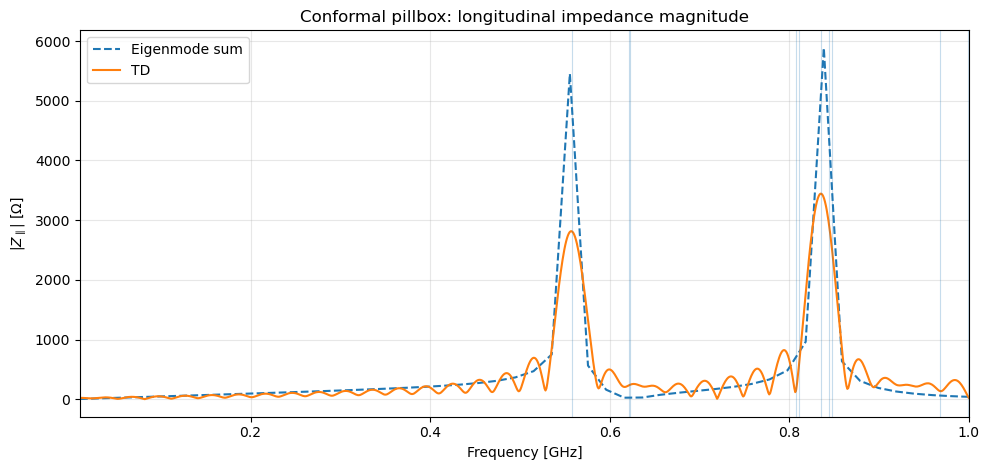

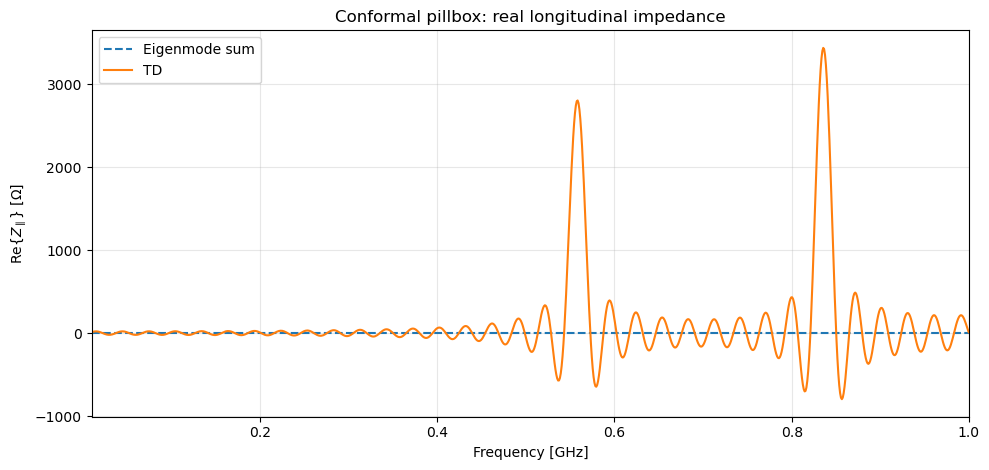

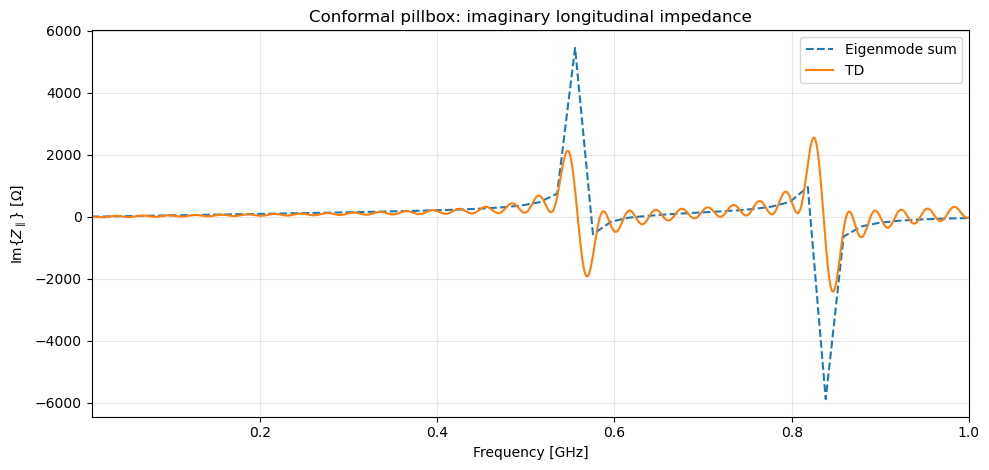

In [24]:
plt.figure(figsize=(10, 4.8))
# plt.plot(
#     f_fd / 1e9,
#     np.abs(Z_fd),
#     label="Driven FD",
# )
plt.plot(
    f_fd / 1e9,
    np.abs(Z_eigen),
    "--",
    label="Eigenmode sum",
)
plt.plot(
    f_td / 1e9,
    np.abs(Z_td),
    label="TD",
)

for f_mode in f_modes:
    if FMIN <= f_mode <= FMAX:
        plt.axvline(
            f_mode / 1e9,
            linewidth=0.8,
            alpha=0.25,
        )

plt.xlim(FMIN / 1e9, FMAX / 1e9)
plt.xlabel("Frequency [GHz]")
plt.ylabel(r"$|Z_\parallel|$ [$\Omega$]")
plt.title("Conformal pillbox: longitudinal impedance magnitude")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 4.8))
# plt.plot(
#     f_fd / 1e9,
#     Z_fd.real,
#     label="Driven FD",
# )
plt.plot(
    f_fd / 1e9,
    Z_eigen.real,
    "--",
    label="Eigenmode sum",
)
plt.plot(
    f_td / 1e9,
    Z_td.real,
    label="TD",
)
plt.xlim(FMIN / 1e9, FMAX / 1e9)
plt.xlabel("Frequency [GHz]")
plt.ylabel(r"$\mathrm{Re}\{Z_\parallel\}$ [$\Omega$]")
plt.title("Conformal pillbox: real longitudinal impedance")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 4.8))
# plt.plot(
#     f_fd / 1e9,
#     Z_fd.imag,
#     label="Driven FD",
# )
plt.plot(
    f_fd / 1e9,
    Z_eigen.imag,
    "--",
    label="Eigenmode sum",
)
plt.plot(
    f_td / 1e9,
    Z_td.imag,
    label="TD",
)
plt.xlim(FMIN / 1e9, FMAX / 1e9)
plt.xlabel("Frequency [GHz]")
plt.ylabel(r"$\mathrm{Im}\{Z_\parallel\}$ [$\Omega$]")
plt.title("Conformal pillbox: imaginary longitudinal impedance")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Individual eigenmode contributions

The following plot shows the contribution of every retained mode separately. This
makes it easy to identify which source-free eigenmode produces each resonance in
the driven impedance.


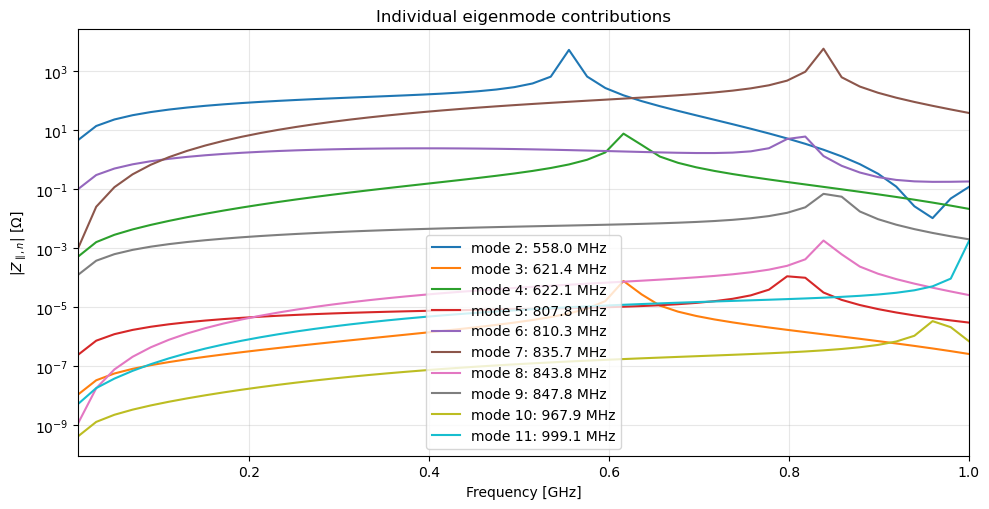

In [25]:
plt.figure(figsize=(10, 5.2))

for n, f_mode in enumerate(f_modes):
    if FMIN <= f_mode <= FMAX:
        plt.plot(
            f_fd / 1e9,
            np.abs(Z_eigen_modes[n]),
            label=f"mode {n + 1}: {f_mode / 1e6:.1f} MHz",
        )

plt.xlabel("Frequency [GHz]")
plt.ylabel(r"$|Z_{\parallel,n}|$ [$\Omega$]")
plt.title("Individual eigenmode contributions")
plt.xlim(FMIN / 1e9, FMAX / 1e9)
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Resonance-position diagnostic

This is intentionally only a simple peak finder on the sampled spectra. For the
lossless FD result, the detected peak amplitude depends strongly on how closely
a sample lands on the pole.


In [26]:
def dominant_peaks(f, Z, relative_prominence=0.02):
    Zabs = np.abs(Z)
    finite = np.isfinite(Zabs)

    if not np.any(finite):
        return np.array([], dtype=int)

    prominence = relative_prominence * np.nanmax(Zabs[finite])

    idx, _ = find_peaks(
        Zabs,
        prominence=prominence,
    )

    return idx


fd_peaks = dominant_peaks(f_fd, Z_fd)
td_peaks = dominant_peaks(f_td, Z_td)

print("FD peaks")
print("--------")
for idx in fd_peaks:
    print(f"{f_fd[idx] / 1e6:10.3f} MHz   |Z|={abs(Z_fd[idx]):.6e} Ohm")

print()
print("TD peaks")
print("--------")
for idx in td_peaks:
    print(f"{f_td[idx] / 1e6:10.3f} MHz   |Z|={abs(Z_td[idx]):.6e} Ohm")


print()
print("Eigenfrequencies inside sweep interval")
print("--------------------------------------")
for f_mode in f_modes:
    if FMIN <= f_mode <= FMAX:
        print(f"{f_mode / 1e6:10.3f} MHz")

print()
print("Nearest driven-FD sample to each eigenfrequency")
print("-----------------------------------------------")
for f_mode in f_modes:
    if FMIN <= f_mode <= FMAX:
        idx = np.abs(f_fd - f_mode).argmin()
        print(
            f"mode {f_mode / 1e6:10.3f} MHz -> "
            f"FD sample {f_fd[idx] / 1e6:10.3f} MHz, "
            f"delta={(f_fd[idx] - f_mode) / 1e6:+8.3f} MHz"
        )

NameError: name 'Z_fd' is not defined

## Field-monitor comparison: \(E_z(z)\) on axis

`monitor_fd.get_components()` and `monitor_td.get_components()` expose the same
monitor data layout, with the first axis corresponding to the configured
monitor frequencies.

For each frequency we extract \(E_z\) on the beam axis. The TD monitor contains
the Gaussian-bunch spectrum and a global time-reference phase, whereas the FD
monitor is the response to a monochromatic 1-A source. Therefore the helper
below determines one complex least-squares factor

\[
\alpha
=
\frac{E_\mathrm{TD}^\mathrm{H}E_\mathrm{FD}}
     {E_\mathrm{TD}^\mathrm{H}E_\mathrm{TD}}
\]

and compares \(\alpha E_\mathrm{TD}\) against \(E_\mathrm{FD}\).

Finally both curves are divided by
\(\max_z|E_{z,\mathrm{FD}}|\). Thus the three plots are a direct test of the
**complex spatial field shape**, independent of the different global
excitation normalization.


In [27]:
fields_fd = monitor_fd.get_components()
fields_td = monitor_td.get_components()

Ez_fd_all = np.asarray(fields_fd["Ez"])
Ez_td_all = np.asarray(fields_td["Ez"])

ix_fd = np.abs(solver_fd.x - XTEST).argmin()
iy_fd = np.abs(solver_fd.y - YTEST).argmin()

ix_td = np.abs(solver_td.x - XTEST).argmin()
iy_td = np.abs(solver_td.y - YTEST).argmin()

z_fd = np.asarray(solver_fd.z)
z_td = np.asarray(solver_td.z)

np.testing.assert_allclose(z_fd, z_td)

Ez_fd_axis = Ez_fd_all[
    :,
    ix_fd,
    iy_fd,
    :,
]

Ez_td_axis = Ez_td_all[
    :,
    ix_td,
    iy_td,
    :,
]

if Ez_fd_axis.shape != Ez_td_axis.shape:
    raise RuntimeError(
        "FD and TD monitor field shapes differ: "
        f"{Ez_fd_axis.shape} vs {Ez_td_axis.shape}"
    )


def align_complex_profile(reference, candidate):
    """Fit one global complex factor multiplying candidate to reference."""
    denominator = np.vdot(candidate, candidate)

    if np.abs(denominator) == 0.0:
        raise RuntimeError("Cannot align a zero TD field profile.")

    alpha = np.vdot(candidate, reference) / denominator

    aligned = alpha * candidate

    relative_error = np.linalg.norm(aligned - reference) / np.linalg.norm(reference)

    return aligned, alpha, relative_error


aligned_td_profiles = []
alignment_factors = []
relative_profile_errors = []

for i, f in enumerate(MONITOR_FREQUENCIES):
    aligned, alpha, error = align_complex_profile(
        Ez_fd_axis[i],
        Ez_td_axis[i],
    )

    aligned_td_profiles.append(aligned)
    alignment_factors.append(alpha)
    relative_profile_errors.append(error)

    print(
        f"{f / 1e6:8.1f} MHz: "
        f"alpha={alpha.real:+.6e}{alpha.imag:+.6e}j, "
        f"relative profile error={error:.3e}"
    )

aligned_td_profiles = np.asarray(aligned_td_profiles)

NameError: name 'monitor_fd' is not defined

In [ ]:
for i, f in enumerate(MONITOR_FREQUENCIES):
    fd_profile = Ez_fd_axis[i]
    td_profile = aligned_td_profiles[i]

    norm = np.max(np.abs(fd_profile))

    if norm == 0.0:
        raise RuntimeError(f"FD Ez profile is zero at {f / 1e6:.1f} MHz.")

    plt.figure(figsize=(10, 4.8))

    plt.plot(
        z_fd,
        np.real(fd_profile) / norm,
        label="FD",
    )

    plt.plot(
        z_td,
        np.real(td_profile) / norm,
        label="TD, globally aligned",
    )

    plt.xlabel("z [m]")
    plt.ylabel(r"$\mathrm{Re}\{E_z\}/\max|E_{z,\mathrm{FD}}|$")
    plt.title(f"On-axis Ez field monitor at {f / 1e6:.1f} MHz")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

## Interpretation

For a successful validation we expect:

- the driven FD, eigenmode and TD calculations to identify the same main resonance positions;
- the eigenfrequencies to coincide with the poles underlying the direct FD response;
- the finite eigenmode sum to reproduce the resonant part of the driven FD impedance, with differences away from the retained modal subspace expected when only a limited number of modes is used;
- the FD low-frequency impedance to approach zero;
- the finite-wake TD peaks to be broader than the ideal lossless FD/eigenmode poles;
- after removal of one global complex excitation factor, the TD and FD
  \(E_z(z)\) monitor profiles to agree closely at the three selected frequencies.

The current eigenmode impedance is intentionally lossless. Resistive-wall/SIBC losses,
complex eigenfrequencies and modal coupling are left for a later extension.

A later field-monitor validation step can normalize the TD monitor fields analytically
by the Gaussian beam-current spectrum so that the **absolute complex field amplitudes**
can be compared without fitting a global scale factor.
